# Pipeline Flow B: Detection, Classification & Counting (Target Set)
Questo notebook gestisce l'esecuzione sequenziale dei singoli moduli del Flow B per la detection, classificazione e conteggio del valore monetario sulle immagini target.


Caricate con successo 142 immagini target da: target_set/


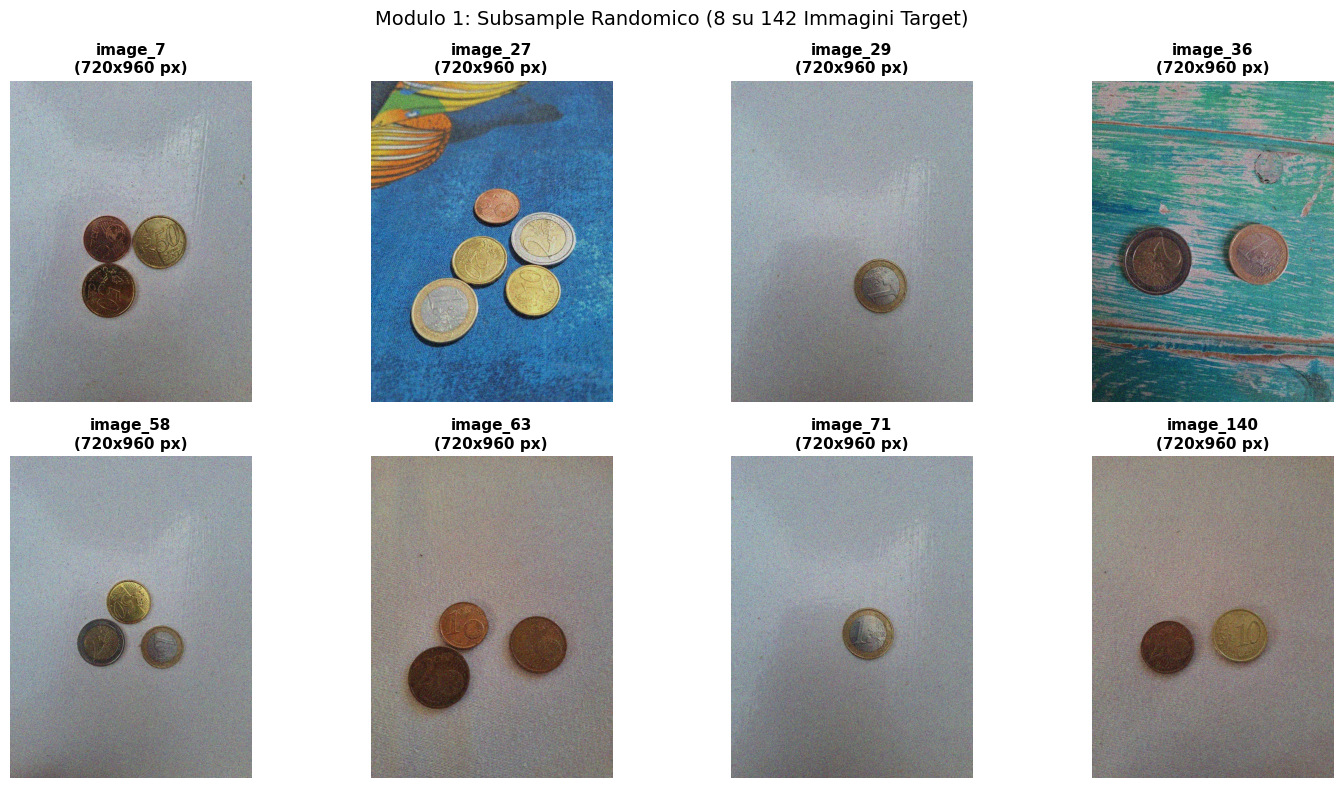

In [2]:
# ==========================================
# MODULO 1: Caricamento Immagini Target
# ==========================================
from module1_load_target import load_target_images, plot_random_sample

# Output in memoria: dizionario con tutte le immagini BGR del target set
target_images = load_target_images()

# Visualizzazione a schermo di un subsample randomico (8 immagini)
plot_random_sample(target_images, n_samples=8, seed=42)


Avvio denoising su 142 immagini target...
  Elaborate 20/142 immagini...
  Elaborate 40/142 immagini...
  Elaborate 60/142 immagini...
  Elaborate 80/142 immagini...
  Elaborate 100/142 immagini...
  Elaborate 120/142 immagini...
  Elaborate 140/142 immagini...
  Elaborate 142/142 immagini...
Denoising completato! Salvate 142 immagini in: C:\Users\Michele\Desktop\UNI\Primo Anno\CV\assignment\m1\project\2cents-X-IPCV\pipeline\artifacts\Flow_B_Target\module2_denoise_for_detection
Grafico riassuntivo del denoising salvato in: C:\Users\Michele\Desktop\UNI\Primo Anno\CV\assignment\m1\project\2cents-X-IPCV\pipeline\artifacts\Flow_B_Target\module2_denoise_for_detection\denoise_summary.png


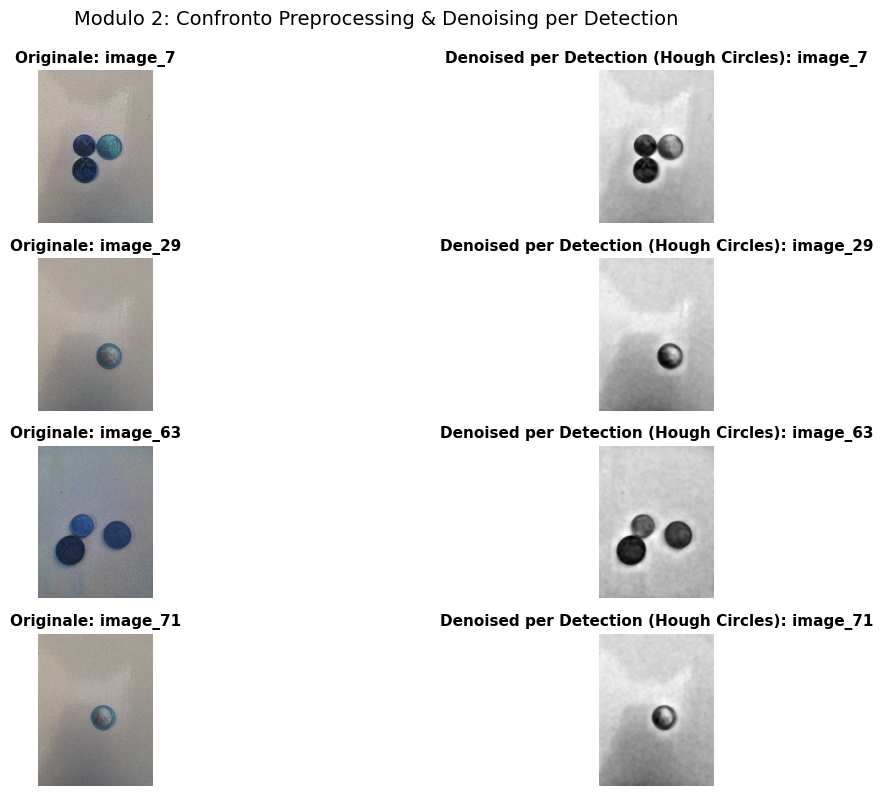

In [3]:
# ==========================================
# MODULO 2: Denoising per Detection (Hough Circles)
# ==========================================
from module2_denoise_for_detection import (
    load_or_create_denoise_params,
    denoise_target_images,
    plot_denoise_comparison
)

# 1. Caricamento parametri da pipeline/conf/Flow_B_Target/denoise_for_detection_params.json
denoise_params = load_or_create_denoise_params()

# 2. Esecuzione del loop di denoising sulle immagini target
# Input: target_images (output del Modulo 1)
# Output: denoised_target_images (dizionario {nome_immagine: immagine_gray_filtrata})
# Serializzazione: pipeline/artifacts/Flow_B_Target/module2_denoise_for_detection/{nome}.png
denoised_target_images = denoise_target_images(target_images, params=denoise_params, save_artifacts=True)

# 3. Visualizzazione a schermo del confronto (Originale vs Denoised per Detection)
plot_denoise_comparison(target_images, denoised_target_images, n_samples=4, seed=42)


Avvio Hough Circles detection su 142 immagini...
Detection completata!
  - Monete totali identificate: 328
  - Data structure salvata in: annotated_images.json
  - Immagini annotate salvate in: C:\Users\Michele\Desktop\UNI\Primo Anno\CV\assignment\m1\project\2cents-X-IPCV\pipeline\artifacts\Flow_B_Target\module3_coin_detection
Grafico riassuntivo della detection salvato in: C:\Users\Michele\Desktop\UNI\Primo Anno\CV\assignment\m1\project\2cents-X-IPCV\pipeline\artifacts\Flow_B_Target\module3_coin_detection\annotated_detection_summary.png


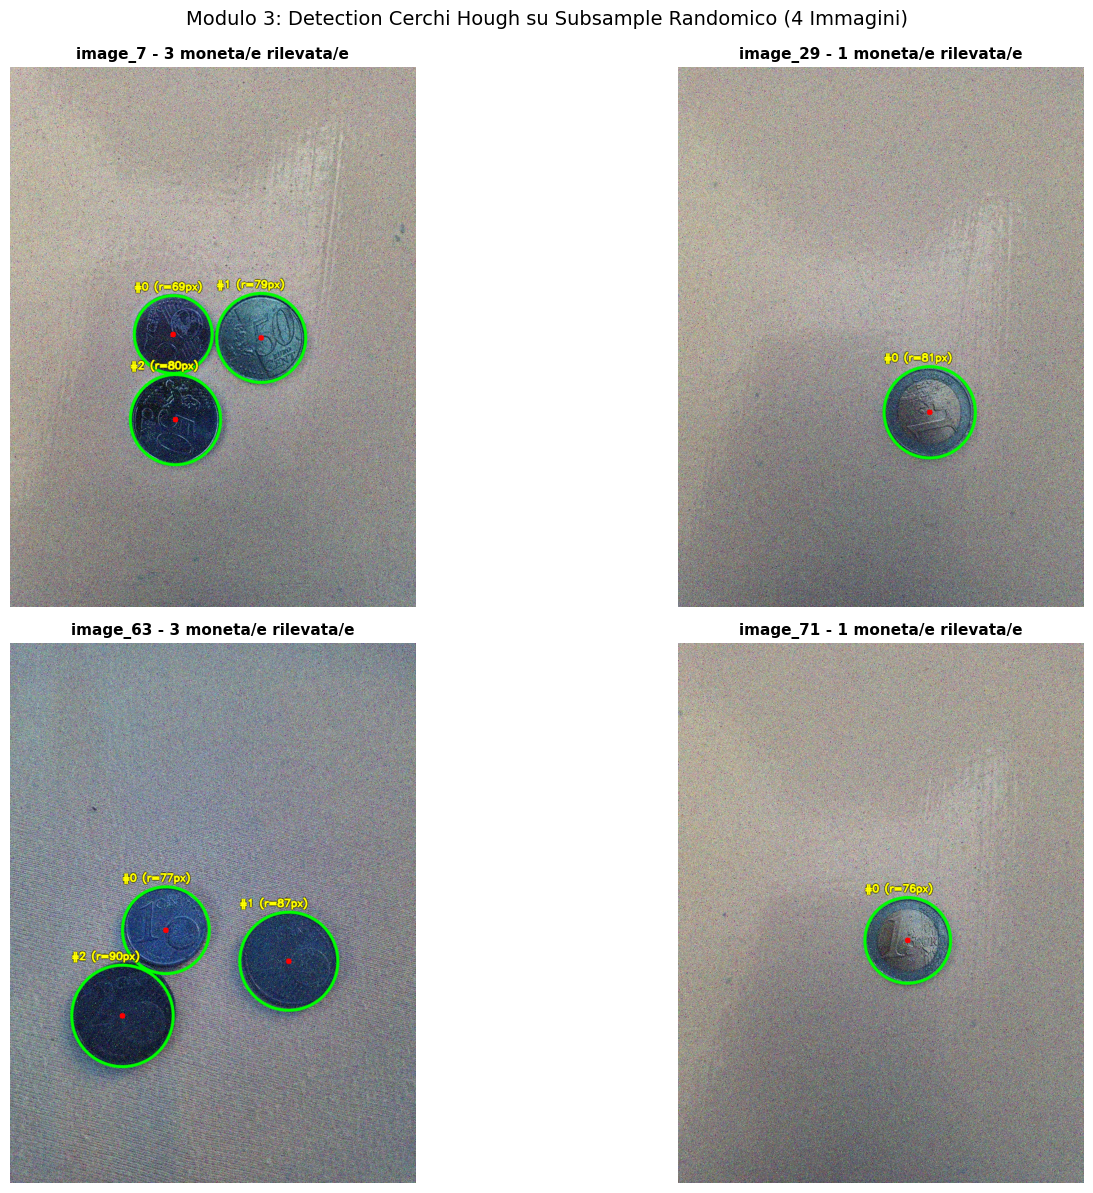

In [4]:
# ==========================================
# MODULO 3: Detection Cerchi (Hough Circles) e Data Structure 'annotated_image'
# ==========================================
from module3_coin_detection import (
    load_or_create_detection_params,
    detect_coins_in_target_images,
    plot_annotated_sample
)

# 1. Caricamento dei parametri da pipeline/conf/Flow_B_Target/coin_detection_params.json
detection_params = load_or_create_detection_params()

# 2. Esecuzione Hough Circles + Edge Support Filtering su ogni immagine target
# Input: target_images (Modulo 1) e denoised_target_images (Modulo 2)
# Output: annotated_images (dizionario con la data structure di ogni immagine e la lista 'coins')
# Serializzazione in artifacts/Flow_B_Target/module3_coin_detection/:
#   - Immagini annotate con cerchi e label ({nome}.png)
#   - Data structure aggregata: annotated_images.json
annotated_images = detect_coins_in_target_images(
    target_images,
    denoised_target_images,
    params=detection_params,
    save_artifacts=True
)

# 3. Visualizzazione a schermo di un subsample casuale di immagini annotate
plot_annotated_sample(annotated_images, target_images, n_samples=4, seed=42)


Parametri Modulo 4 caricati da: denoise_colored_params.json
Avvio denoising a colori su 142 immagini target...
Parametri applicati: NLM_h=12.0, NLM_hColor=20.0, Median=3x3
  [20/142] Elaborate 20 immagini su 142...
  [40/142] Elaborate 40 immagini su 142...
  [60/142] Elaborate 60 immagini su 142...
  [80/142] Elaborate 80 immagini su 142...
  [100/142] Elaborate 100 immagini su 142...
  [120/142] Elaborate 120 immagini su 142...
  [140/142] Elaborate 140 immagini su 142...
  [142/142] Elaborate 142 immagini su 142...
Denoising completato con successo!
  - Immagini salvate in: C:\Users\Michele\Desktop\UNI\Primo Anno\CV\assignment\m1\project\2cents-X-IPCV\pipeline\artifacts\Flow_B_Target\module4_denoise_colored
  - Manifest metadati con foreign key salvato in: denoised_images_metadata.json


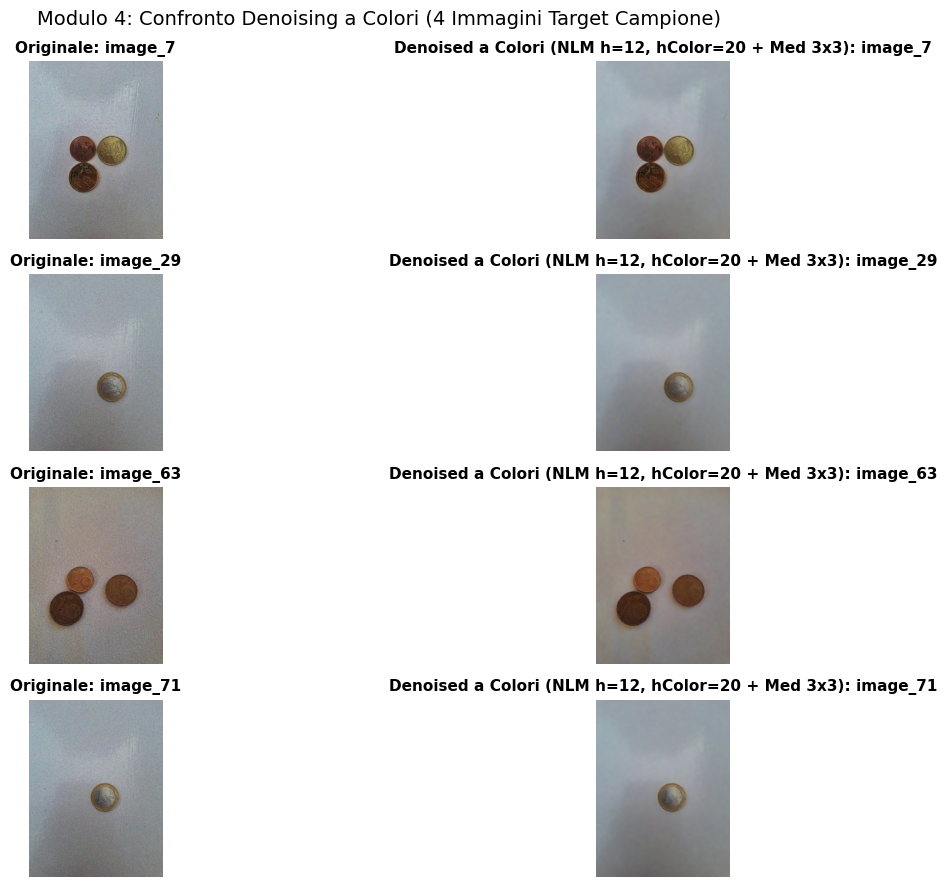

In [5]:
# ==========================================
# MODULO 4: Denoising a Colori per Classificazione (NLM Colored + Median 3x3)
# ==========================================
from module4_denoise_colored import (
    load_or_create_denoise_colored_params,
    denoise_target_images_colored,
    plot_denoise_colored_sample
)

# 1. Caricamento parametri da pipeline/conf/Flow_B_Target/denoise_colored_params.json
denoise_colored_params = load_or_create_denoise_colored_params()

# 2. Esecuzione del denoising a colori su ogni immagine target
# Input: target_images (output Modulo 1)
# Output: denoised_target_images_colored (dizionario {image_name: immagine_denoised_rgb})
# Serializzazione in artifacts/Flow_B_Target/module4_denoise_colored/:
#   - Immagini denoised ({image_name}.png)
#   - Manifest con foreign_key verso annotated_images.json: denoised_images_metadata.json
denoised_target_images_colored = denoise_target_images_colored(
    target_images,
    params=denoise_colored_params,
    save_artifacts=True
)

# 3. Visualizzazione a schermo di un subsample casuale (Originale vs Denoised Colored)
plot_denoise_colored_sample(target_images, denoised_target_images_colored, n_samples=4, seed=42)


Parametri Modulo 5 caricati da: coin_color_classification_params.json
Profili colore Flusso A caricati da: color_profiles.json
Avvio classificazione cromatica su 328 monete (142 immagini)...
  [50/328] Monete classificate...
  [100/328] Monete classificate...
  [150/328] Monete classificate...
  [300/328] Monete classificate...
  [328/328] Monete classificate...
Aggiornato 'annotated_images.json' in: artifacts\Flow_B_Target\module3_coin_detection\annotated_images.json
Salvati artefatti Modulo 5 in: module5_coin_color_classification/

Riepilogo Classificazione Cromatica delle Monete:
  - copper : 131 monete ( 39.9%)
  - gold   : 122 monete ( 37.2%)
  - 1 euro :  42 monete ( 12.8%)
  - 2 euro :  33 monete ( 10.1%)


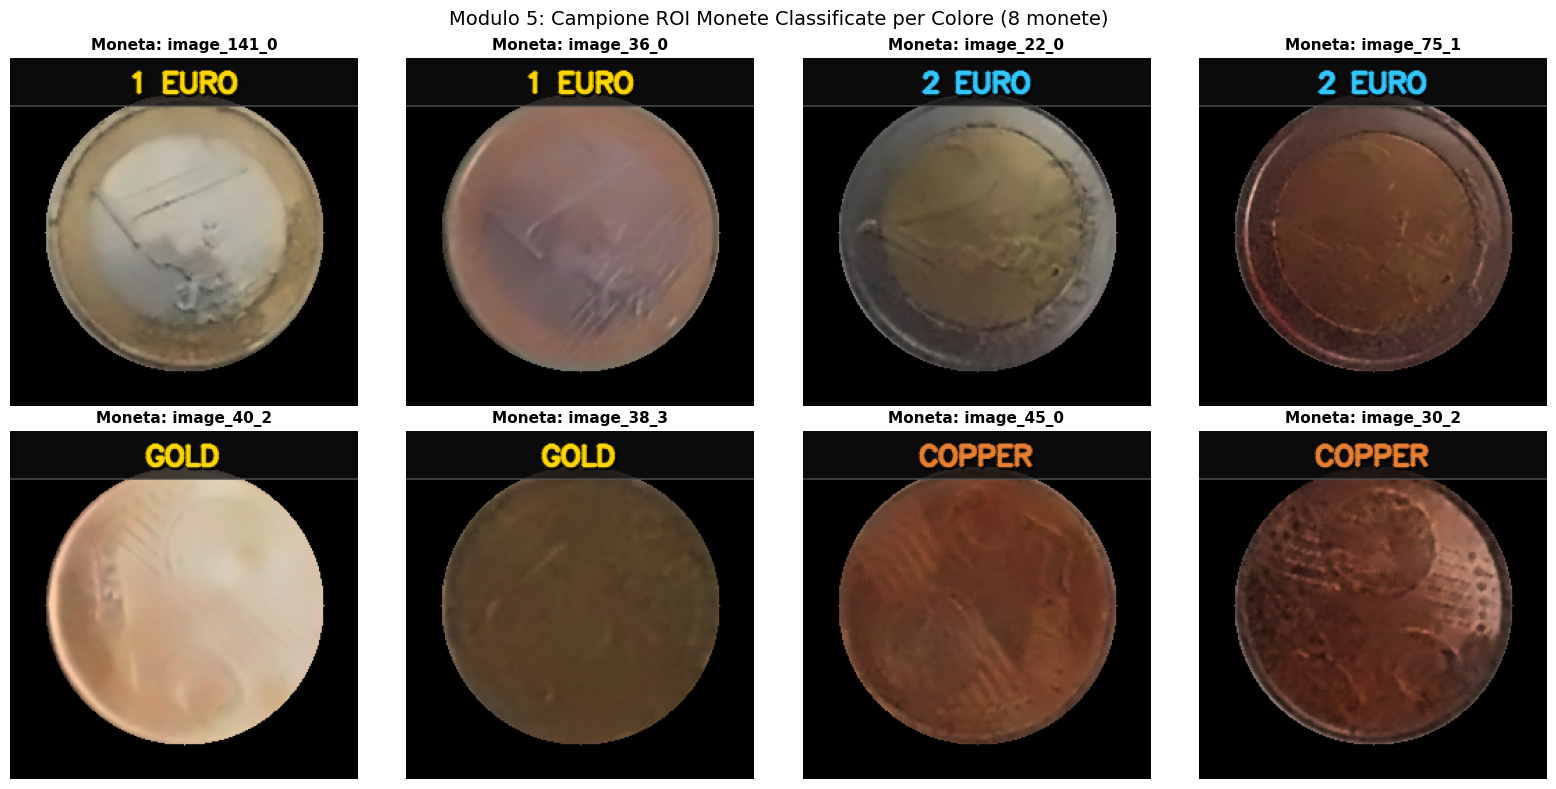

In [6]:
# ==========================================
# MODULO 5: Classificazione Cromatica delle Monete (1 euro, 2 euro, gold, copper)
# ==========================================
from module5_coin_color_classification import (
    load_or_create_classification_params,
    load_reference_color_profiles,
    classify_all_coins,
    plot_classified_coins_sample
)

# 1. Caricamento parametri di classificazione e profili colore del Flusso A
class_params = load_or_create_classification_params()
color_profiles = load_reference_color_profiles(class_params.get("color_profiles_path"))

# 2. Esecuzione classificazione su tutte le monete rilevate:
#    - Estrae la ROI circolare mascherata da ciascuna immagine denoised a colori
#    - Confronta i colori con i profili estratti nel Flusso A
#    - Classifica in: '1 euro', '2 euro', 'gold', 'copper'
#    - Aggiunge in append il campo 'class' a ogni moneta in annotated_images.json
#    - Salva le ROI etichettate ({nome_file}_{coin_id}.png) negli artifacts
annotated_images, labeled_rois = classify_all_coins(
    denoised_images=denoised_target_images_colored,
    annotated_images=annotated_images,
    profiles=color_profiles,
    params=class_params,
    save_artifacts=True
)

# 3. Visualizzazione a schermo di un subsample di ROI classificate con le rispettive classi
plot_classified_coins_sample(annotated_images, labeled_rois, n_samples=8, seed=42)
